# Лабораторная работа № 6
## Ансамбли моделей машинного обучения. Часть 2

**Цель.** Изучить стекинг, многослойный персептрон и методы МГУА на задаче регрессии.

**Задание.** Выбрать и подготовить набор данных. Разделить его методом `train_test_split`, обучить стекинг и многослойный персептрон. В дополнительной части обучить линейную модель MULTI и нелинейную модель MIA из библиотеки `gmdh`. Сравнить качество всех моделей на одной тестовой выборке.

Материалы курса

- [Задание лабораторной работы](https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_ENSEMBLES_2)
- [Стекинг](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/ensembles/stacking.ipynb)
- [Введение в нейронные сети](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/ensembles/neural_networks.ipynb)
- [Введение в МГУА](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/ensembles/gmdh.ipynb)

## 1. Загрузка библиотек и данных

В файле `day.csv` каждая строка соответствует одному дню работы сети Capital Bikeshare в Вашингтоне. По календарным и погодным признакам оценим общее суточное число прокатов `cnt`. Используем дневную выборку за 2011–2012 гг. из Bike Sharing Dataset. Авторы — Hadi Fanaee-T и João Gama. Лицензия CC BY 4.0. [Карточка набора UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) · [Исходный архив](https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip)

Для запуска нужны ядро Jupyter, `numpy`, `pandas`, `matplotlib` и `scikit-learn` версии 1.2 или новее. Для воспроизведения дополнительной части под Windows можно выбрать 64-разрядный Python 3.11 и установить `gmdh==1.0.3` с `numpy<2`. [Пакеты gmdh на PyPI](https://pypi.org/project/gmdh/1.0.3/#files)

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = Path('day.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('lab6') / DATA_PATH
if not DATA_PATH.is_file():
    DATA_PATH = Path('labs_ml') / DATA_PATH

data = pd.read_csv(DATA_PATH, parse_dates=['dteday'])
print(f'Наблюдений — {len(data)}, столбцов — {data.shape[1]}.')
print(f'Период — с {data["dteday"].min():%d.%m.%Y} по {data["dteday"].max():%d.%m.%Y}.')
display(data.head())

Наблюдений — 731, столбцов — 16.
Период — с 01.01.2011 по 31.12.2012.


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Анализ и подготовка данных

Проверим типы столбцов, пропуски, совпадающие строки и распределение целевой переменной.

,Тип данных,Пропуски,Уникальные значения
instant,int64,0,731
dteday,datetime64[us],0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,3
temp,float64,0,499


Повторяющихся строк — 0.
Равенство cnt = casual + registered выполняется для всех дней: True.


,Прокатов в день
count,731.0
mean,4504.3
std,1937.2
min,22.0
25%,3152.0
50%,4548.0
75%,5956.0
max,8714.0


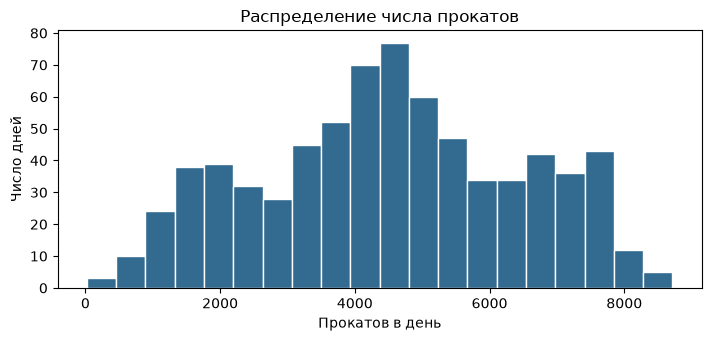

In [2]:
display(pd.DataFrame({
    'Тип данных': data.dtypes.astype(str),
    'Пропуски': data.isna().sum(),
    'Уникальные значения': data.nunique(),
}))
print(f'Повторяющихся строк — {data.duplicated().sum()}.')
print(f'Равенство cnt = casual + registered выполняется для всех дней: '
      f'{data["cnt"].eq(data["casual"] + data["registered"]).all()}.')
display(data['cnt'].describe().round(1).to_frame('Прокатов в день'))

fig, ax = plt.subplots(figsize=(7, 3.3), layout='constrained')
ax.hist(data['cnt'], bins=20, color='#336a90', edgecolor='white')
ax.set(title='Распределение числа прокатов', xlabel='Прокатов в день', ylabel='Число дней')
plt.show()

В исходных данных пропусков и совпадающих строк нет. Столбцы `casual` и `registered` содержат число прокатов незарегистрированных и зарегистрированных пользователей. Их сумма равна `cnt`, поэтому оба столбца исключены во избежание утечки целевой переменной.

Для модели оставим календарные признаки и погодные измерения. `instant` служит индексом, а `dteday` пригодится для подписи примеров прогнозов. Сезон оставим как компактное описание годового цикла, поэтому `mnth` исключим. Признак `workingday` определяется по дню недели и праздничному дню. Из двух близких показателей температуры оставим измеренную температуру `temp`.

`season`, `weekday` и `weathersit` закодируем методом one-hot. При наличии пропусков в признаках числовые значения заполняются медианой, а категории — модой. Числовые признаки стандартизируются перед обучением.

In [3]:
numeric_features = ['yr', 'holiday', 'temp', 'hum', 'windspeed']
categorical_features = ['season', 'weekday', 'weathersit']
X = data[numeric_features + categorical_features]
y = data['cnt']

preprocessor = ColumnTransformer([
    ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric_features),
    ('categorical', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
    ), categorical_features),
])
print(f'Входных признаков — {X.shape[1]}.')

Входных признаков — 8.


## 3. Разбиение на обучающую и тестовую выборки

Выделим 20% дней методом `train_test_split` с перемешиванием и зафиксируем `random_state=42`. Тестовые дни используются для итоговой оценки. Такое разбиение оценивает качество на отложенных днях из того же периода. Для оценки прогноза на будущий период понадобилось бы хронологическое разбиение.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED,
)

display(pd.DataFrame({
    'Число дней': [len(y_train), len(y_test)],
    'Среднее число прокатов': [y_train.mean(), y_test.mean()],
}, index=['Обучающая выборка', 'Тестовая выборка']).round(1))

,Число дней,Среднее число прокатов
Обучающая выборка,584,4561.0
Тестовая выборка,147,4279.4


## 4. Обучение моделей

### Стекинг

На первом уровне используем гребневую регрессию, случайный лес и градиентный бустинг. Они описывают разные зависимости между признаками и числом прокатов. `StackingRegressor` делит обучающую выборку на пять блоков. Для каждой строки базовые модели формируют прогнозы, обучившись на остальных блоках. По этим прогнозам обучается гребневая регрессия второго уровня. Для итоговых прогнозов базовые модели обучаются на всей обучающей выборке.

Каждая базовая модель имеет собственный конвейер обработки. На каждом шаге кросс-валидации он обучается по четырём обучающим блокам.

In [5]:
base_estimators = [
    ('ridge', Ridge(alpha=1.0)),
    ('forest', RandomForestRegressor(
        n_estimators=150, min_samples_leaf=3, random_state=SEED,
    )),
    ('boosting', GradientBoostingRegressor(
        n_estimators=150, max_depth=3, random_state=SEED,
    )),
]
stacking = StackingRegressor(
    estimators=[
        (name, make_pipeline(clone(preprocessor), estimator))
        for name, estimator in base_estimators
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
)
stacking.fit(X_train, y_train)
print(f'Стекинг обучен: {len(stacking.estimators_)} базовые модели, 5 блоков.')

Стекинг обучен: 3 базовые модели, 5 блоков.


### Многослойный персептрон

Используем `MLPRegressor` с двумя скрытыми слоями на 32 и 16 нейронов, активацией ReLU и оптимизатором Adam. Для ранней остановки выделяется 10% обучающих наблюдений. `TransformedTargetRegressor` стандартизирует число прокатов при обучении и возвращает прогноз в исходных единицах.

In [6]:
mlp = TransformedTargetRegressor(
    regressor=make_pipeline(
        clone(preprocessor),
        MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation='relu',
            solver='adam',
            alpha=0.01,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=30,
            max_iter=1000,
            random_state=SEED,
        ),
    ),
    transformer=StandardScaler(),
)
mlp.fit(X_train, y_train)
mlp_regressor = mlp.regressor_.named_steps['mlpregressor']
print(f'Персептрон обучен за {mlp_regressor.n_iter_} эпох.')

Персептрон обучен за 103 эпох.


### Дополнительная часть. МГУА

MULTI последовательно добавляет признаки к лучшим линейным моделям предыдущего ряда. MIA строит квадратичные полиномы от пар переменных. На следующих рядах такие полиномы строятся от выходов лучших моделей предыдущего ряда. Обе модели сравнивают кандидатов по критерию регулярности. Библиотека выделяет для этого 25% переданной ей обучающей выборки. [Документация MULTI](https://bauman-team.github.io/GMDH_book/multi.html) · [Документация MIA](https://bauman-team.github.io/GMDH_book/mia.html)

In [7]:
gmdh_predictions = {}

try:
    import gmdh
except ModuleNotFoundError as error:
    if error.name != 'gmdh':
        raise
    print('Для запуска дополнительной части установите gmdh в ядро Jupyter.')
else:
    gmdh_preprocessor = clone(preprocessor)
    X_train_gmdh = gmdh_preprocessor.fit_transform(X_train)
    X_test_gmdh = gmdh_preprocessor.transform(X_test)

    target_scaler = StandardScaler()
    y_train_gmdh = target_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()
    criterion = gmdh.Criterion(gmdh.CriterionType.REGULARITY)
    gmdh_models = [
        ('МГУА MULTI', gmdh.Multi(), {'k_best': 3}),
        ('МГУА MIA', gmdh.Mia(), {'k_best': 4, 'polynomial_type': gmdh.PolynomialType.QUADRATIC}),
    ]
    for name, model, parameters in gmdh_models:
        model.fit(
            X_train_gmdh, y_train_gmdh, criterion=criterion,
            test_size=0.25, **parameters,
        )
        scaled_prediction = model.predict(X_test_gmdh)
        gmdh_predictions[name] = target_scaler.inverse_transform(
            scaled_prediction.reshape(-1, 1)
        ).ravel()
        print(f'{name} обучена.')

МГУА MULTI обучена.
МГУА MIA обучена.


## 5. Сравнение моделей на тестовой выборке

Основная метрика — **MAE**, средняя абсолютная ошибка в числе прокатов. **RMSE** тоже измеряется в прокатах и сильнее реагирует на крупные ошибки. Для MAE и RMSE меньшее значение лучше. **R²** показывает качество по сравнению с постоянным прогнозом, равным среднему фактическому значению на тесте. Чем ближе R² к единице, тем лучше.

In [8]:
predictions = {
    'Стекинг': stacking.predict(X_test),
    'Персептрон': mlp.predict(X_test),
    **gmdh_predictions,
}
results = pd.DataFrame.from_dict({
    name: {
        'MAE': mean_absolute_error(y_test, prediction),
        'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'R²': r2_score(y_test, prediction),
    }
    for name, prediction in predictions.items()
}, orient='index').sort_values('MAE')
display(results.round({'MAE': 1, 'RMSE': 1, 'R²': 3}))

examples = pd.DataFrame({
    'Дата': data.loc[y_test.index, 'dteday'].dt.strftime('%d.%m.%Y'),
    'Фактическое число': y_test,
    **{name: np.rint(prediction).astype(int) for name, prediction in predictions.items()},
})
display(examples.sort_index().head().reset_index(drop=True))

,MAE,RMSE,R²
Стекинг,461.4,647.5,0.895
Персептрон,568.3,782.4,0.847
МГУА MULTI,603.0,811.7,0.836
МГУА MIA,732.4,956.1,0.772


,Дата,Фактическое число,Стекинг,Персептрон,МГУА MULTI,МГУА MIA
0,03.01.2011,1349,1241,1212,1322,1399
1,11.01.2011,1263,718,874,751,1196
2,24.01.2011,1416,991,656,927,857
3,31.01.2011,1501,1018,1097,738,1197
4,01.02.2011,1360,793,1109,907,1335


На диаграмме слева сравним MAE. На графике справа сопоставим фактические значения и прогнозы модели с наименьшей MAE. Точки на диагонали соответствуют точному прогнозу.

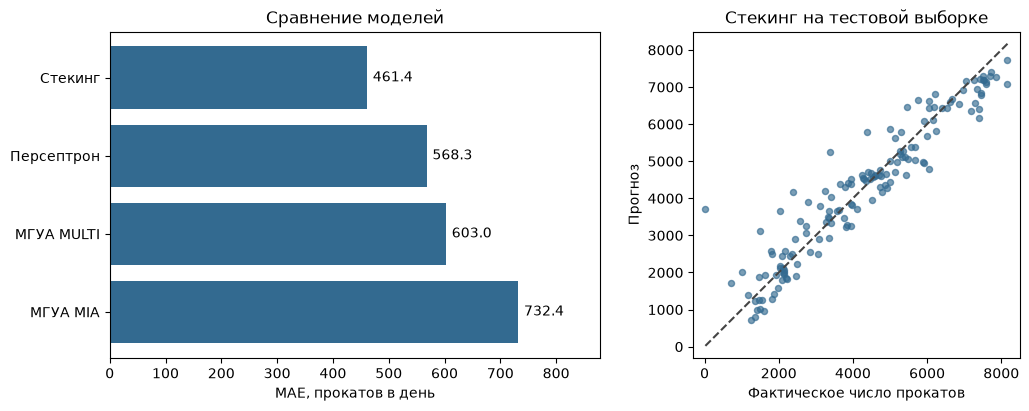

In [9]:
best_name = results.index[0]
best_prediction = predictions[best_name]
lower = min(y_test.min(), best_prediction.min())
upper = max(y_test.max(), best_prediction.max())
padding = 0.04 * (upper - lower)

fig, (ax_metrics, ax_predictions) = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
bars = ax_metrics.barh(results.index, results['MAE'], color='#336a90')
ax_metrics.bar_label(bars, fmt='%.1f', padding=4)
ax_metrics.invert_yaxis()
ax_metrics.set(
    title='Сравнение моделей',
    xlabel='MAE, прокатов в день',
    xlim=(0, results['MAE'].max() * 1.2),
)
ax_predictions.scatter(y_test, best_prediction, s=19, alpha=0.65, color='#336a90')
ax_predictions.plot([lower, upper], [lower, upper], '--', color='#444444')
ax_predictions.set(
    title=f'{best_name} на тестовой выборке',
    xlabel='Фактическое число прокатов',
    ylabel='Прогноз',
    xlim=(lower - padding, upper + padding),
    ylim=(lower - padding, upper + padding),
    aspect='equal',
)
plt.show()

## Вывод

1. Из 731 дня 584 использованы для обучения и 147 для тестирования. Подготовка признаков и стандартизация целевой переменной для персептрона и МГУА выполнены по обучающим данным.
2. Стекинг показал наименьшие MAE (461,4) и RMSE (647,5) и наибольший R² (0,895). У персептрона MAE составила 568,3 проката в день.
3. MAE линейной модели MULTI составила 603,0 проката в день, а нелинейной MIA — 732,4.